# Part C

In [ ]:
import os , sys
import zipfile
import json
import numpy as np
import pandas as pd
from itertools import combinations
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.tree import ExtraTreeClassifier
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder, Normalizer
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score, train_test_split, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, mean_squared_error,
    mean_absolute_error, r2_score, mean_absolute_percentage_error,
    roc_curve, classification_report
)
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib
import gc, time
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED
import os, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try:
    import shap
except ImportError:
    pass  
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


In [2]:
CKPT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

USE_ARTICLE_PARAMS = True

if USE_ARTICLE_PARAMS:
    ADA_N_ESTIMATORS = 50
    RF_N_ESTIMATORS  = 50
    REG_N_ESTIMATORS = 100
    N_CV_FOLDS       = 5
    CV_SUBSAMPLE     = None
else:
    ADA_N_ESTIMATORS = 15
    RF_N_ESTIMATORS  = 30
    REG_N_ESTIMATORS = 50
    N_CV_FOLDS       = 5
    CV_SUBSAMPLE     = 150_000

CONFIG_TAG = f"article{int(USE_ARTICLE_PARAMS)}_ada{ADA_N_ESTIMATORS}_rf{RF_N_ESTIMATORS}_reg{REG_N_ESTIMATORS}_sub{CV_SUBSAMPLE}"

RFE_CKPT         = os.path.join(CKPT_DIR, 'ckpt_rfe_selection.pkl')
NORM_CKPT        = os.path.join(CKPT_DIR, 'ckpt_normalized.pkl')
CV_CKPT          = os.path.join(CKPT_DIR, f'ckpt_cv_boosted_rf_{CONFIG_TAG}.pkl')
FINAL_MODEL_CKPT = os.path.join(CKPT_DIR, f'ckpt_boosted_rf_final_{CONFIG_TAG}.joblib')
REG_CKPT         = os.path.join(CKPT_DIR, f'ckpt_rf_regressor_{CONFIG_TAG}.joblib')

print(f"USE_ARTICLE_PARAMS = {USE_ARTICLE_PARAMS}")
print(f"CONFIG_TAG = {CONFIG_TAG}")

def make_boosted_rf():
    return AdaBoostClassifier(
        estimator=RandomForestClassifier(
            n_estimators=RF_N_ESTIMATORS,
            criterion="entropy",
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ),
        n_estimators=ADA_N_ESTIMATORS,
        learning_rate=1.0,
        random_state=42
    )

def make_extra_tree():
    return ExtraTreeClassifier(
        criterion="entropy",
        class_weight="balanced",
        random_state=42
    )

USE_ARTICLE_PARAMS = True
CONFIG_TAG = article1_ada50_rf50_reg100_subNone


In [ ]:
KAGGLE_INPUT = '/kaggle/input'

IN_KAGGLE = os.path.isdir(KAGGLE_INPUT) or 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
IN_COLAB  = (not IN_KAGGLE) and os.path.exists('/var/colab/hostname')

def find_dream_root(base):

    best_root, best_count = None, 0
    for root, dirs, files in os.walk(base):
        json_subdirs = [
            d for d in dirs
            if any(f.endswith('.json')
                   for f in os.listdir(os.path.join(root, d))
                   if os.path.isfile(os.path.join(root, d, f)))
        ]
        if json_subdirs:
            total_json = sum(
                len([f for f in os.listdir(os.path.join(root, d)) if f.endswith('.json')])
                for d in json_subdirs
            )
            if total_json > best_count:
                best_root, best_count = root, total_json
    return best_root

def extract_all_zips_recursive(base):

    while True:
        zips_found = []
        for root, dirs, files in os.walk(base):
            for f in files:
                if f.lower().endswith('.zip'):
                    zips_found.append(os.path.join(root, f))
        if not zips_found:
            break
        for zpath in zips_found:
            dest = os.path.dirname(zpath)
            print(f"Extracting: {zpath}")
            with zipfile.ZipFile(zpath, 'r') as z:
                z.extractall(dest)
            os.remove(zpath)

if IN_COLAB:
    print("Environment detected : Colab")
    from google.colab import drive
    drive.mount('/content/drive')

    dream_path   = '/content/drive/MyDrive/Master_TSA/Datasets/Dream dataset/snd1156-1-1.zip'
    extract_path = '/content/DREAM'
    os.makedirs(extract_path, exist_ok=True)

    import zipfile
    with zipfile.ZipFile(dream_path, 'r') as z:
        z.extractall(extract_path)

    extract_all_zips_recursive(extract_path)   

    dream_root = find_dream_root(extract_path)
    if dream_root is None:
        raise RuntimeError(
            "No subfolder containing .json files found after extraction.\n"
            "Check the structure under /content/DREAM."
        )
    extract_path = dream_root
    print(f"DREAM dataset found in: {extract_path}")

else:
    print("Environment detected : Kaggle")
    dream_root = find_dream_root(KAGGLE_INPUT)
    if dream_root is None:
        raise RuntimeError(
            "DREAM dataset not found in /kaggle/input/\n"
            "Verify that the dataset is correctly added to the notebook via 'Add Data'."
        )
    extract_path = dream_root
    print(f"DREAM dataset found in: {extract_path}")

Environment detected : Kaggle
DREAM dataset found in: /kaggle/input/datasets/rymjaballah/dream-dataset/snd1156-1-1/data/DREAM2020_SND1156-001-V1.0/DREAMdataset


In [ ]:
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

SEGMENT_SIZE = 25

JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
          'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
          'HandLeft', 'HandRight']

JOINT_MAP_RAW = {
    'head':           'Head',
    'sholder_center': 'ShoulderCenter',
    'sholder_left':   'ShoulderLeft',
    'sholder_right':  'ShoulderRight',
    'elbow_left':     'ElbowLeft',
    'elbow_right':    'ElbowRight',
    'wrist_left':     'WristLeft',
    'wrist_right':    'WristRight',
    'hand_left':      'HandLeft',
    'hand_right':     'HandRight',
}

ANGLE_TRIPLETS = [
    ('Head',          'ShoulderCenter', 'ShoulderLeft'),
    ('Head',          'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
    ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
    ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
    ('ShoulderRight', 'ElbowRight',     'WristRight'),
    ('ElbowLeft',     'WristLeft',      'HandLeft'),
    ('ElbowRight',    'WristRight',     'HandRight'),
]

N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))

MAX_IN_FLIGHT   = N_WORKERS * 4   # maximum number of files being processed at one time
CHECKPOINT_EVERY   = 200          # saves every 200 files
CHECKPOINT_SECONDS = 180          # And at least every 3 minutes, even if <200 files are created

CHECKPOINT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'
CHECKPOINT_PKL = os.path.join(CHECKPOINT_DIR, 'feat_checkpoint.pkl')

print(f"CPU cores used for parallel processing : {N_WORKERS}")
print(f"Files being processed simultaneously (max) : {MAX_IN_FLIGHT}")


def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

def euclidean_dist(A, B):
    return float(np.sqrt(np.sum((A - B) ** 2)))

def angle_between(P1, P2, P3):
    v1 = P1 - P2; v2 = P3 - P2
    cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
    return float(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

def extract_features_arrays(seg_arrays, gaze_arrays, normative):
    feats = {}

    # Dv - 45 distances
    means = {j: seg_arrays[j].mean(axis=0) for j in JOINTS}
    for jA, jB in combinations(JOINTS, 2):
        feats[f'{jA}_{jB}_dist'] = euclidean_dist(means[jA], means[jB])

    # Wv - 9 angles
    for P1n, P2n, P3n in ANGLE_TRIPLETS:
        feats[f'{P1n}_{P2n}_{P3n}_angle'] = angle_between(means[P1n], means[P2n], means[P3n])

    # Dv - 8 gaze features
    vectors = {}
    for name in ['head', 'eye']:
        G_arr = gaze_arrays.get(name)
        if G_arr is not None and G_arr.shape[0] > 0:
            G = G_arr.mean(axis=0)
            mag = np.linalg.norm(G) + 1e-9
            feats[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(G[0]/mag, -1, 1))))
            feats[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(G[1]/mag, -1, 1))))
            feats[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(G[2]/mag, -1, 1))))
            vectors[name] = G
        else:
            feats[f'{name}_alpha'] = feats[f'{name}_beta'] = feats[f'{name}_gamma'] = np.nan

    if 'head' in vectors and 'eye' in vectors:
        H, E = vectors['head'], vectors['eye']
        H_mag = np.linalg.norm(H) + 1e-9
        E_mag = np.linalg.norm(E) + 1e-9
        cos_t = np.dot(E, H) / (E_mag * H_mag)
        theta = np.arccos(np.clip(cos_t, -1, 1))
        feats['gaze_angle_EH'] = float(np.degrees(theta))
        feats['gaze_zone_phi'] = float(np.degrees(np.arctan2(H_mag*np.sin(theta), E_mag+H_mag*np.cos(theta))))
    else:
        feats['gaze_angle_EH'] = feats['gaze_zone_phi'] = np.nan

    # Sv - 36 std features (30 skeleton + 6 gaze)
    for j in JOINTS:
        for ax_i, ax in enumerate(['x','y','z']):
            col = f'skeleton_{j.lower()}_{ax}'
            feats[f'{col}_std'] = float(seg_arrays[j][:, ax_i].std())
    for name in ['head', 'eye']:
        G_arr = gaze_arrays.get(name)
        for ax_i, ax in enumerate(['rx','ry','rz']):
            col = f'{name}_gaze_{ax}'
            feats[f'{col}_std'] = float(G_arr[:, ax_i].std()) if G_arr is not None else np.nan

    # Nav - 5
    feats.update(normative)
    return feats

# ── Main pipeline ──

def process_json_file(fpath):
    with open(fpath) as f:
        data = json.load(f)

    p         = safe_first(data.get('participant', {}))
    ados      = data.get('ados', {})
    ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    t         = data.get('task', {}) if isinstance(data.get('task'), dict) else {}

    comm   = ados_data.get('communication')
    inter  = ados_data.get('interaction')
    module = ados_data.get('module')
    label  = assign_label(module, comm, inter)
    if label is None:
        return []   # Participants outside the TEEN criteria, skip

    pid        = p.get('id', p.get('child_id'))
    age_months = p.get('ageInMonths', p.get('age_months'))
    gender_raw = str(p.get('gender', 'unknown'))
    cond_raw   = data.get('condition', p.get('condition', 'SHT'))
    difficulty_raw = t.get('difficultyLevel', t.get('task_ability', 0))
    ability_raw= str(t.get('ability', t.get('task_ability', 'unknown')))
    ados_score = (comm or 0) + (inter or 0)

    skel = data.get('skeleton', {})
    hg   = data.get('head_gaze', {})
    eg   = data.get('eye_gaze',  {})

    joint_series = {}
    for raw_key, canon in JOINT_MAP_RAW.items():
        joint = skel.get(raw_key, {})
        joint_series[canon] = build_xyz_array(joint, ('x', 'y', 'z')) if isinstance(joint, dict) else None

    gaze_series = {
        'head': build_xyz_array(hg, ('rx', 'ry', 'rz')),
        'eye':  build_xyz_array(eg, ('rx', 'ry', 'rz')),
    }

    # Session length = maximum of available sets
    lengths = [a.shape[0] for a in joint_series.values() if a is not None]
    lengths += [a.shape[0] for a in gaze_series.values() if a is not None]
    if not lengths:
        return []
    n_frames = max(lengths)

    n_segs = n_frames // SEGMENT_SIZE
    if n_segs == 0:
        return []

    feats_list = []
    for i in range(n_segs):
        s, e = i * SEGMENT_SIZE, (i + 1) * SEGMENT_SIZE

        seg_arrays = {}
        for j in JOINTS:
            arr = joint_series[j]
            if arr is not None and s < arr.shape[0]:
                seg_arrays[j] = arr[s:min(e, arr.shape[0])]
                if len(seg_arrays[j]) < SEGMENT_SIZE:
                    pad = np.full((SEGMENT_SIZE - len(seg_arrays[j]), 3), np.nan)
                    seg_arrays[j] = np.vstack([seg_arrays[j], pad])
            else:
                seg_arrays[j] = np.full((SEGMENT_SIZE, 3), np.nan)

        seg_gaze = {}
        for name, arr in gaze_series.items():
            if arr is not None and s < arr.shape[0]:
                sliced = arr[s:min(e, arr.shape[0])]
                if len(sliced) < SEGMENT_SIZE:
                    pad = np.full((SEGMENT_SIZE - len(sliced), 3), np.nan)
                    sliced = np.vstack([sliced, pad])
                seg_gaze[name] = sliced
            else:
                seg_gaze[name] = None

        normative = {
            'participant_ageInMonths': age_months,
            'age_group':    0,
            'gender':       gender_raw,
            'task_ability': ability_raw,
            'task_difficulty': difficulty_raw,
        }

        feats = extract_features_arrays(seg_arrays, seg_gaze, normative)
        feats['participant_id'] = pid
        feats['label']          = label
        feats['ados_score']     = ados_score
        feats['age_months']     = age_months
        feats['condition']      = cond_raw

        feats_list.append(feats)

    return feats_list


all_json_files = []
for user_dir in sorted(os.listdir(extract_path)):
    user_path = os.path.join(extract_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    for fname in sorted(os.listdir(user_path)):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(user_path, fname))

print(f"JSON files detected: {len(all_json_files)}")


processed_set = set()
all_feats = []
if os.path.exists(CHECKPOINT_PKL):
    with open(CHECKPOINT_PKL, 'rb') as f:
        ck = pickle.load(f)
    processed_set = ck.get('processed', set())
    all_feats     = ck.get('feats', [])
    print(f"Checkpoint found -> {len(processed_set)} files already processed, "
          f"{len(all_feats)} segments already extracted. Resuming.")

remaining_files = [f for f in all_json_files if f not in processed_set]
print(f"Remaining files to process: {len(remaining_files)}")

def save_checkpoint():
    with open(CHECKPOINT_PKL, 'wb') as f:
        pickle.dump({'feats': all_feats, 'processed': processed_set}, f)

errors = []
n_done = len(processed_set)
t0 = time.time()


if remaining_files:
    file_iter = iter(remaining_files)
    last_ckpt_time = time.time()

    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {}
        for _ in range(min(MAX_IN_FLIGHT, len(remaining_files))):
            fp = next(file_iter)
            futures[ex.submit(process_json_file, fp)] = fp

        pbar = tqdm(total=len(remaining_files), desc="Extraction features")
        while futures:
            done, _ = wait(futures, return_when=FIRST_COMPLETED)
            for fut in done:
                fp = futures.pop(fut)
                try:
                    feats = fut.result()
                    all_feats.extend(feats)
                except Exception as e:
                    errors.append((fp, str(e)))
                processed_set.add(fp)
                n_done += 1
                pbar.update(1)

                # Resubmits a new file to keep the pool full
                try:
                    nf = next(file_iter)
                    futures[ex.submit(process_json_file, nf)] = nf
                except StopIteration:
                    pass

                now = time.time()
                if n_done % CHECKPOINT_EVERY == 0 or (now - last_ckpt_time) > CHECKPOINT_SECONDS:
                    save_checkpoint()
                    last_ckpt_time = now
                    elapsed = now - t0
                    print(f"[checkpoint] {n_done}/{len(all_json_files)} files processed "
                          f"({elapsed:.0f}s elapsed for this run)")
        pbar.close()

save_checkpoint()  # final checkpoint

feat_df = pd.DataFrame(all_feats)
gc.collect()

# Different encoding of categorical columns
feat_df['gender']       = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
feat_df['age_group']    = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
feat_df['participant_ageInMonths'] = feat_df['age_months']

print("=" * 60)
print(f"Files processed     : {n_done} / {len(all_json_files)}")
print(f"Total segments      : {len(feat_df)}")
print(f"Features per segment: {feat_df.shape[1]}")
print(f"Unique participants : {feat_df['participant_id'].nunique()}")
print(f"Label distribution  : {feat_df['label'].value_counts().to_dict()}")
print(f"Errors              : {len(errors)}")
if errors:
    for p, e in errors[:5]:
        print(f"  {p} -> {e}")

display(feat_df.head())


CPU cores used for parallel processing : 3
Files being processed simultaneously (max) : 12
JSON files detected: 3121
Remaining files to process: 3121


Extraction features:   0%|          | 0/3121 [00:00<?, ?it/s]

[checkpoint] 200/3121 files processed (74s elapsed for this run)
[checkpoint] 400/3121 files processed (146s elapsed for this run)
[checkpoint] 600/3121 files processed (224s elapsed for this run)
[checkpoint] 800/3121 files processed (301s elapsed for this run)
[checkpoint] 1000/3121 files processed (370s elapsed for this run)
[checkpoint] 1200/3121 files processed (436s elapsed for this run)
[checkpoint] 1400/3121 files processed (505s elapsed for this run)
[checkpoint] 1600/3121 files processed (593s elapsed for this run)
[checkpoint] 1800/3121 files processed (675s elapsed for this run)
[checkpoint] 2000/3121 files processed (760s elapsed for this run)
[checkpoint] 2200/3121 files processed (835s elapsed for this run)
[checkpoint] 2400/3121 files processed (925s elapsed for this run)
[checkpoint] 2600/3121 files processed (1021s elapsed for this run)
[checkpoint] 2800/3121 files processed (1112s elapsed for this run)
[checkpoint] 3000/3121 files processed (1215s elapsed for this ru

,Head_ShoulderCenter_dist,Head_ShoulderLeft_dist,Head_ShoulderRight_dist,Head_ElbowLeft_dist,Head_ElbowRight_dist,Head_WristLeft_dist,Head_WristRight_dist,Head_HandLeft_dist,Head_HandRight_dist,ShoulderCenter_ShoulderLeft_dist,...,participant_ageInMonths,age_group,gender,task_ability,task_difficulty,participant_id,label,ados_score,age_months,condition
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,66,3,1,2,1,10,Autistic Disorder,14,66,RET


participant_id
31    0.447055
14    0.370312
15    0.342550
32    0.320548
44    0.279568
50    0.276669
30    0.219143
19    0.214715
60    0.198749
11    0.189001
9     0.184719
74    0.182636
59    0.181942
13    0.177524
62    0.169490
69    0.165743
36    0.142000
10    0.130919
54    0.127161
80    0.118794
72    0.113442
61    0.111979
78    0.109998
52    0.107429
67    0.105139
12    0.101826
71    0.100713
37    0.097388
26    0.096771
65    0.096003
58    0.093211
77    0.086318
70    0.085392
42    0.081222
5     0.078282
8     0.074971
40    0.070811
56    0.069377
35    0.057497
81    0.056368
33    0.052877
66    0.052816
38    0.048157
55    0.045401
4     0.044515
21    0.043423
46    0.042234
6     0.040541
79    0.039720
75    0.038367
51    0.037251
20    0.037181
76    0.034872
3     0.034392
29    0.022765
73    0.020655
23    0.020261
43    0.019538
34    0.018645
47    0.017574
41    0.014288


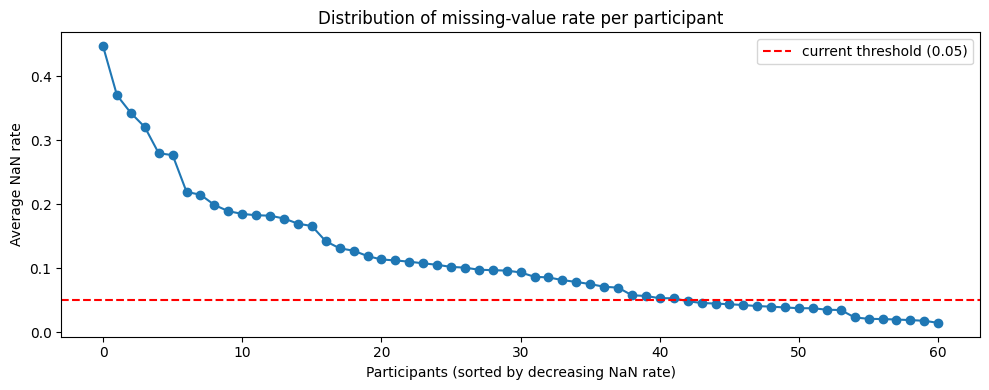


Top 10 participants with the most NaN:
participant_id
31    0.447055
14    0.370312
15    0.342550
32    0.320548
44    0.279568
50    0.276669
30    0.219143
19    0.214715
60    0.198749
11    0.189001
dtype: float64
Excluded participants (missing data) : 7 -> [31, 14, 15, 32, 44, 50, 30]
Remaining participants : 54  (article awaiting 54)
Train : 46 participants | Test : 8 participants
Distribution train: {'Autistic Disorder': 35, 'ASD (AS, PDD)': 11}
Distribution test : {'Autistic Disorder': 6, 'ASD (AS, PDD)': 2}
Number of samples per train: 753604
Number of test samples: 159843
Number of features before selection : 103
Selected features : 53
['Head_ShoulderCenter_dist', 'Head_ShoulderLeft_dist', 'Head_ShoulderRight_dist', 'Head_ElbowLeft_dist', 'Head_ElbowRight_dist', 'Head_WristLeft_dist', 'Head_WristRight_dist', 'Head_HandLeft_dist', 'Head_HandRight_dist', 'ShoulderCenter_ShoulderLeft_dist'] ...
Checkpoint backup -> /kaggle/working/ckpt_rfe_selection.pkl


In [ ]:


if os.path.exists(RFE_CKPT):
    print(f"Checkpoint found : {RFE_CKPT} -> loading (RFE not redone).")
    with open(RFE_CKPT, 'rb') as f:
        _ck = pickle.load(f)
    FEATURE_COLS      = _ck['FEATURE_COLS']
    X_train_sel       = _ck['X_train_sel']
    X_test_sel        = _ck['X_test_sel']
    y_train_clf       = _ck['y_train_clf']
    y_test_clf        = _ck['y_test_clf']
    y_train_reg       = _ck['y_train_reg']
    y_test_reg        = _ck['y_test_reg']
    le                = _ck['le']
    selected_features = _ck['selected_features']
    train_pids        = _ck['train_pids']
    test_pids_unique  = _ck['test_pids_unique']
    print(f"Number of samples per train : {X_train_sel.shape[0]}")
    print(f"Number of test samples  : {X_test_sel.shape[0]}")
    print(f"Selected features : {len(selected_features)}")
    print(selected_features[:10], '...')

else:
    EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months','condition'}
    FEATURE_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
    X_raw = feat_df[FEATURE_COLS].copy()
    y_clf_raw = feat_df['label']
    y_reg_raw = feat_df['ados_score']

    # 1. Remove columns that are entirely NaN
    X_raw = X_raw.dropna(axis=1, how='all')
    FEATURE_COLS = list(X_raw.columns)

    nan_rate_by_pid = (
        feat_df.assign(**{c: X_raw[c] for c in FEATURE_COLS})
               .groupby('participant_id')[FEATURE_COLS]
               .apply(lambda g: g.isna().mean().mean())
    )

    nan_rate_sorted = nan_rate_by_pid.sort_values(ascending=False)
    print(nan_rate_sorted.to_string())

    plt.figure(figsize=(10, 4))
    plt.plot(range(len(nan_rate_sorted)), nan_rate_sorted.values, marker='o')
    plt.xlabel("Participants (sorted by decreasing NaN rate)")
    plt.ylabel("Average NaN rate")
    plt.axhline(y=0.05, color='r', linestyle='--', label='current threshold (0.05)')
    plt.title("Distribution of missing-value rate per participant")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("\nTop 10 participants with the most NaN:")
    print(nan_rate_sorted.head(10))
    N_TO_EXCLUDE = 7
    excluded_pids = nan_rate_sorted.head(N_TO_EXCLUDE).index.tolist()
    print(f"Excluded participants (missing data) : {len(excluded_pids)} -> {excluded_pids}")




    keep_mask = ~feat_df['participant_id'].isin(excluded_pids).values
    feat_df_clean = feat_df.loc[keep_mask].reset_index(drop=True)
    X_raw          = X_raw.loc[keep_mask].reset_index(drop=True)
    y_clf_raw      = y_clf_raw.loc[keep_mask].reset_index(drop=True)
    y_reg_raw      = y_reg_raw.loc[keep_mask].reset_index(drop=True)

    n_participants_final = feat_df_clean['participant_id'].nunique()
    print(f"Remaining participants : {n_participants_final}  (article awaiting 54)")

    participant_label = feat_df_clean.groupby('participant_id')['label'].agg(
        lambda s: s.value_counts().idxmax()
    )

    train_ids, test_ids = train_test_split(
        participant_label.index.to_numpy(),
        test_size=8,
        stratify=participant_label.values,
        random_state=42
    )
    print(f"Train : {len(train_ids)} participants | Test : {len(test_ids)} participants")
    print("Distribution train:", participant_label.loc[train_ids].value_counts().to_dict())
    print("Distribution test :", participant_label.loc[test_ids].value_counts().to_dict())

    train_mask = feat_df_clean['participant_id'].isin(train_ids).values
    test_mask  = feat_df_clean['participant_id'].isin(test_ids).values

    # 4. Median imputation calculated on X_train only
    train_medians = X_raw[train_mask].median(numeric_only=True)
    X_raw = X_raw.fillna(train_medians)

    le = LabelEncoder()
    y_clf = le.fit_transform(y_clf_raw)
    y_reg = y_reg_raw.values

    X_train_raw = X_raw.values[train_mask]
    X_test_raw  = X_raw.values[test_mask]
    y_train_clf = y_clf[train_mask]
    y_test_clf  = y_clf[test_mask]
    y_train_reg = y_reg[train_mask]
    y_test_reg  = y_reg[test_mask]

    train_pids = feat_df_clean['participant_id'].values[train_mask]
    test_pids_unique = sorted(test_ids.tolist())

    print(f"Number of samples per train: {X_train_raw.shape[0]}")
    print(f"Number of test samples: {X_test_raw.shape[0]}")
    print(f"Number of features before selection : {len(FEATURE_COLS)}")

    # 5. RFE fitted to X_train only
    rf_base = RandomForestClassifier(
        n_estimators=50,
        criterion='entropy',
        random_state=42,
        n_jobs=-1
    )
    rfe = RFE(estimator=rf_base, n_features_to_select=53, step=5)
    rfe.fit(X_train_raw, y_train_clf)

    X_train_sel = rfe.transform(X_train_raw)
    X_test_sel  = rfe.transform(X_test_raw)

    selected_features = [FEATURE_COLS[i] for i, s in enumerate(rfe.support_) if s]
    print(f'Selected features : {len(selected_features)}')
    print(selected_features[:10], '...')

    with open(RFE_CKPT, 'wb') as f:
        pickle.dump({
            'FEATURE_COLS': FEATURE_COLS,
            'X_train_sel': X_train_sel, 'X_test_sel': X_test_sel,
            'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
            'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
            'le': le, 'selected_features': selected_features,
            'train_pids': train_pids,
            'test_pids_unique': test_pids_unique,
        }, f)
    print(f"Checkpoint backup -> {RFE_CKPT}")

Part C

In [ ]:


from itertools import combinations

JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
          'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
          'HandLeft', 'HandRight']

ANGLE_TRIPLETS = [
    ('Head',          'ShoulderCenter', 'ShoulderLeft'),
    ('Head',          'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
    ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
    ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
    ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
    ('ShoulderRight', 'ElbowRight',     'WristRight'),
    ('ElbowLeft',     'WristLeft',      'HandLeft'),
    ('ElbowRight',    'WristRight',     'HandRight'),
]

SOCIAL_FEATURES = []
for name in ['head', 'eye']:
    SOCIAL_FEATURES += [f'{name}_alpha', f'{name}_beta', f'{name}_gamma']
SOCIAL_FEATURES += ['gaze_angle_EH', 'gaze_zone_phi']
for name in ['head', 'eye']:
    for ax in ['rx', 'ry', 'rz']:
        SOCIAL_FEATURES.append(f'{name}_gaze_{ax}_std')

MOTOR_FEATURES = []
for jA, jB in combinations(JOINTS, 2):
    MOTOR_FEATURES.append(f'{jA}_{jB}_dist')
for P1n, P2n, P3n in ANGLE_TRIPLETS:
    MOTOR_FEATURES.append(f'{P1n}_{P2n}_{P3n}_angle')
for j in JOINTS:
    for ax in ['x', 'y', 'z']:
        MOTOR_FEATURES.append(f'skeleton_{j.lower()}_{ax}_std')

TARGET_ASD  = "label"           # multiclass: 'ASD (AS, PDD)' / 'Autistic Disorder'
TARGET_ADOS = "ados_score"      # continuous: comm + inter
GROUP_COL   = "participant_id"  # for StratifiedGroupKFold

if 'feat_df' in dir():
    missing_social = [c for c in SOCIAL_FEATURES if c not in feat_df.columns]
    missing_motor  = [c for c in MOTOR_FEATURES  if c not in feat_df.columns]
    if missing_social:
        print(f"SOCIAL_FEATURES missing from feat_df: {missing_social}")
    if missing_motor:
        print(f"MOTOR_FEATURES missing from feat_df: {missing_motor}")
    SOCIAL_FEATURES = [c for c in SOCIAL_FEATURES if c in feat_df.columns]
    MOTOR_FEATURES  = [c for c in MOTOR_FEATURES  if c in feat_df.columns]

print(f"SOCIAL_FEATURES ({len(SOCIAL_FEATURES)}) : {SOCIAL_FEATURES}")
print(f"MOTOR_FEATURES  ({len(MOTOR_FEATURES)}) : {MOTOR_FEATURES[:10]} ...")

SOCIAL_FEATURES (14) : ['head_alpha', 'head_beta', 'head_gamma', 'eye_alpha', 'eye_beta', 'eye_gamma', 'gaze_angle_EH', 'gaze_zone_phi', 'head_gaze_rx_std', 'head_gaze_ry_std', 'head_gaze_rz_std', 'eye_gaze_rx_std', 'eye_gaze_ry_std', 'eye_gaze_rz_std']
MOTOR_FEATURES  (84) : ['Head_ShoulderCenter_dist', 'Head_ShoulderLeft_dist', 'Head_ShoulderRight_dist', 'Head_ElbowLeft_dist', 'Head_ElbowRight_dist', 'Head_WristLeft_dist', 'Head_WristRight_dist', 'Head_HandLeft_dist', 'Head_HandRight_dist', 'ShoulderCenter_ShoulderLeft_dist'] ...


In [ ]:

class DREAMDataset(Dataset):
   
    def __init__(self, df: pd.DataFrame, social_cols: list, motor_cols: list,
                 target_asd: str, target_ados: str,
                 scaler: StandardScaler = None, fit_scaler: bool = True):
        self.social_cols = social_cols
        self.motor_cols  = motor_cols
        all_cols = social_cols + motor_cols

        X = df[all_cols].values.astype(np.float32)
        if scaler is not None:
            X = scaler.fit_transform(X) if fit_scaler else scaler.transform(X)
        self.scaler = scaler

        n_social = len(social_cols)
        self.X_social = torch.tensor(X[:, :n_social], dtype=torch.float32)
        self.X_motor  = torch.tensor(X[:, n_social:], dtype=torch.float32)

        y_asd_raw = df[target_asd].values
        if y_asd_raw.dtype == object:
            y_asd_raw = LabelEncoder().fit_transform(y_asd_raw)
        self.y_asd  = torch.tensor(y_asd_raw.astype(np.int64), dtype=torch.long)
        self.y_ados = torch.tensor(df[target_ados].values.astype(np.float32),
                                    dtype=torch.float32)

    def __len__(self):
        return len(self.y_asd)

    def __getitem__(self, idx):
        return (self.X_social[idx], self.X_motor[idx],
                self.y_asd[idx], self.y_ados[idx])


def make_weighted_sampler(y: np.ndarray) -> WeightedRandomSampler:
    y = np.asarray(y).astype(np.int64)
    class_counts  = np.bincount(y)
    class_weights = 1.0 / np.clip(class_counts, 1, None)
    sample_weights = class_weights[y]
    return WeightedRandomSampler(
        weights=torch.tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True
    )

In [ ]:



CONDITION_MAP = {'RET': 0, 'SHT': 1}   # binary encoding


class DREAMDatasetFiLM(DREAMDataset):
 
    def __init__(self, df, social_cols, motor_cols,
                 target_asd, target_ados,
                 scaler=None, fit_scaler=True,
                 cond_col: str = 'condition'):
        super().__init__(df, social_cols, motor_cols,
                         target_asd, target_ados,
                         scaler=scaler, fit_scaler=fit_scaler)
        cond_raw = df[cond_col].astype(str).map(CONDITION_MAP).fillna(-1).astype(int)
        self.cond = torch.tensor(cond_raw.values, dtype=torch.long)

    def __getitem__(self, idx):
        x_s, x_m, y_a, y_o = super().__getitem__(idx)
        return x_s, x_m, y_a, y_o, self.cond[idx]


In [ ]:

import math

class FeatureTokenizer(nn.Module):
    def __init__(self, n_features: int, d_model: int):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_features, d_model))
        self.bias   = nn.Parameter(torch.empty(n_features, d_model))
        d_sqrt_inv = 1 / math.sqrt(d_model)
        nn.init.uniform_(self.weight, -d_sqrt_inv, d_sqrt_inv)
        nn.init.uniform_(self.bias,   -d_sqrt_inv, d_sqrt_inv)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (B, F)  ->  (B, F, d_model)
        return x.unsqueeze(-1) * self.weight + self.bias


class TransformerEncoderBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_ff: int, dropout: float):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, n_heads,
                                           dropout=dropout, batch_first=True)
        self.ff    = nn.Sequential(
            nn.Linear(d_model, d_ff), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.drop  = nn.Dropout(dropout)

    def forward(self, x):
        
        h = self.norm1(x)
        h, _ = self.attn(h, h, h)
        x = x + self.drop(h)
        h = self.norm2(x)
        x = x + self.drop(self.ff(h))
        return x


class FTTransformerEncoder(nn.Module):
  
    def __init__(self, n_features: int, d_model: int = 128,
                 n_heads: int = 4, n_layers: int = 3,
                 d_ff: int = 256, dropout: float = 0.1):
        super().__init__()
        self.d_model    = d_model
        self.n_features = n_features
        self.tokenizer  = FeatureTokenizer(n_features, d_model)
        self.cls_token  = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed  = nn.Parameter(
            torch.zeros(1, n_features + 1, d_model))
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(d_model, n_heads, d_ff, dropout)
            for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed,  std=0.02)

    def forward(self, x: torch.Tensor, return_sequence: bool = False):
        B = x.size(0)
        tokens = self.tokenizer(x)                         # (B, F, d)
        cls    = self.cls_token.expand(B, -1, -1)          # (B, 1, d)
        tokens = torch.cat([cls, tokens], dim=1)           # (B, F+1, d)
        tokens = tokens + self.pos_embed
        for block in self.blocks:
            tokens = block(tokens)
        tokens = self.norm(tokens)
        if return_sequence:
            return tokens[:, 0], tokens                    # CLS, full sequence
        return tokens[:, 0]                                # CLS only  (B, d)

In [ ]:

class CrossAttentionBlock(nn.Module):
  
    def __init__(self, d_model: int, n_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.cross_attn = nn.MultiheadAttention(
            d_model, n_heads, dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, seq_social: torch.Tensor,
                seq_motor: torch.Tensor) -> torch.Tensor:
        # seq_social: (B, Ns, d)  — Ns = n_social_features + 1 (CLS)
        # seq_motor : (B, Nm, d)  — Nm = n_motor_features  + 1 (CLS)
        out, attn_weights = self.cross_attn(
            seq_social, seq_motor, seq_motor,
            need_weights=True, average_attn_weights=False
        )                                                  # (B, Ns, d)
        out = self.drop(out)
        return self.norm(seq_social + out), attn_weights    # residual + weights for inspection



In [ ]:
class InterpretableFusion(nn.Module):
   
    def __init__(self, d_model: int):
        super().__init__()
        self.gate = nn.Linear(d_model * 2, 2)

    def forward(self, z_social: torch.Tensor,
                z_motor: torch.Tensor):
        concat = torch.cat([z_social, z_motor], dim=-1)    # (B, 2d)
        alpha  = torch.softmax(self.gate(concat), dim=-1)   # (B, 2), rows sum to 1
        alpha_s, alpha_m = alpha[:, 0:1], alpha[:, 1:2]
        z_final = alpha_s * z_social + alpha_m * z_motor   # (B, d)
        return z_final, alpha_s, alpha_m


class MultiTaskHead(nn.Module):
    def __init__(self, d_model: int, n_classes: int = 2,
                 dropout: float = 0.2):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Linear(d_model, d_model // 2), nn.GELU(),
            nn.LayerNorm(d_model // 2), nn.Dropout(dropout))
        self.asd_head  = nn.Linear(d_model // 2, n_classes)
        self.ados_head = nn.Linear(d_model // 2, 1)

    def forward(self, z):
        h = self.shared(z)
        return self.asd_head(h), self.ados_head(h).squeeze(-1)

In [ ]:
class FiLMConditioner(nn.Module):

    def __init__(self, d_model: int, n_conditions: int = 2, hidden: int = 64):
        super().__init__()
        self.embed = nn.Embedding(n_conditions, d_model)  # 1 vector/condition
        # Shared MLP → projects to [γ, β] of size d_model each
        self.mlp = nn.Sequential(
            nn.Linear(d_model, hidden),
            nn.GELU(),
            nn.Linear(hidden, d_model * 2),   
        )
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, z: torch.Tensor, cond: torch.Tensor) -> torch.Tensor:
        """
        z    : (B, d_model)  — CLS token to modulate
        cond : (B,)          — condition indices (0=RET, 1=SHT)
        """
        emb = self.embed(cond)                    # (B, d_model)
        out = self.mlp(emb)                       # (B, 2*d_model)
        gamma, beta = out.chunk(2, dim=-1)        # (B, d_model) each
        gamma = gamma + 1.0
        return gamma * z + beta                   # FiLM : affine feature-wise

In [ ]:

class DREAMASDNet(nn.Module):
    """
    Social + Motor FT-Transformer → Cross-Attention →
    Interpretable Fusion → Multi-Task Head
    """
    def __init__(self, n_social: int, n_motor: int,
                 d_model: int = 128, n_heads: int = 4,
                 n_layers: int = 3, d_ff: int = 256,
                 dropout: float = 0.1, n_classes: int = 2):
        super().__init__()
        self.enc_social = FTTransformerEncoder(
            n_social, d_model, n_heads, n_layers, d_ff, dropout)
        self.enc_motor  = FTTransformerEncoder(
            n_motor,  d_model, n_heads, n_layers, d_ff, dropout)
        self.cross_attn = CrossAttentionBlock(d_model, n_heads, dropout)
        self.fusion     = InterpretableFusion(d_model)
        self.head       = MultiTaskHead(d_model, n_classes, dropout)

    def forward(self, x_social, x_motor):
        cls_s, seq_s = self.enc_social(x_social, return_sequence=True)  # (B,d), (B,Ns,d)
        cls_m, seq_m = self.enc_motor(x_motor,  return_sequence=True)  # (B,d), (B,Nm,d)
        fused_seq, attn_w = self.cross_attn(seq_s, seq_m)               # (B, Ns, d)
        fused_cls = fused_seq[:, 0]                                     # (B, d)  attended CLS
        z_final, alpha_s, alpha_m = self.fusion(fused_cls, cls_m)
        logits_asd, pred_ados = self.head(z_final)
        return logits_asd, pred_ados, alpha_s, alpha_m

In [ ]:


class DREAMASDNetFiLM(nn.Module):

    def __init__(self, n_social: int, n_motor: int,
                 d_model: int = 128, n_heads: int = 4,
                 n_layers: int = 3, d_ff: int = 256,
                 dropout: float = 0.1, n_classes: int = 2,
                 n_conditions: int = 2, film_hidden: int = 64):
        super().__init__()
        self.enc_social = FTTransformerEncoder(
            n_social, d_model, n_heads, n_layers, d_ff, dropout)
        self.enc_motor  = FTTransformerEncoder(
            n_motor,  d_model, n_heads, n_layers, d_ff, dropout)
        self.cross_attn = CrossAttentionBlock(d_model, n_heads, dropout)
        self.fusion     = InterpretableFusion(d_model)
        self.head       = MultiTaskHead(d_model, n_classes, dropout)

        # A single conditioner shared by both branches.
        # This forces the condition to have a consistent effect on Social AND Motor,
        # which is more interpretable than two independent conditioners.
        self.film = FiLMConditioner(d_model, n_conditions, film_hidden)

    def forward(self, x_social, x_motor, cond=None):
        
        # Encoding with full sequences (for cross-attention)
        cls_s, seq_s = self.enc_social(x_social, return_sequence=True)
        cls_m, seq_m = self.enc_motor (x_motor,  return_sequence=True)

        # Cross-attention: social tokens "read" motor tokens
        fused_seq, attn_w = self.cross_attn(seq_s, seq_m)
        fused_cls = fused_seq[:, 0]    # social CLS enriched by cross-attention

        if cond is not None:
            # We modulate the fused CLS (social × motor) AND the pure motor CLS
            # so the condition influences both branches via the α fusion
            fused_cls = self.film(fused_cls, cond)
            cls_m     = self.film(cls_m,     cond)

        # Interpretable fusion α_social / α_motor 
        z_final, alpha_s, alpha_m = self.fusion(fused_cls, cls_m)

        # Multi-task head 
        logits_asd, pred_ados = self.head(z_final)
        return logits_asd, pred_ados, alpha_s, alpha_m


In [ ]:
class MultiTaskLoss(nn.Module):
    def __init__(self, lambda_ados: float = 0.5,
                 class_weights: torch.Tensor = None):
        super().__init__()
        self.ce  = nn.CrossEntropyLoss(weight=class_weights)
        self.mse = nn.MSELoss()
        self.lam = lambda_ados

    def forward(self, logits_asd, pred_ados, y_asd, y_ados):
        loss_asd  = self.ce(logits_asd, y_asd)
        loss_ados = self.mse(pred_ados, y_ados)
        return loss_asd + self.lam * loss_ados, loss_asd, loss_ados

In [ ]:
def compute_asd_metrics(y_true, y_pred, y_prob):
    """All metrics in 'macro' to be comparable with Part A
    (Boosted RF uses average='macro' — see cell 23)."""
    return {
        "accuracy" : accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall"   : recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1"       : f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc"      : roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.0,
    }

def compute_ados_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "mae" : mean_absolute_error(y_true, y_pred),
        "rmse": np.sqrt(mse),
        "r2"  : r2_score(y_true, y_pred),
    }

def aggregate_by_participant(pids, y_true, y_pred, y_prob, y_true_ados, y_pred_ados):

    df = pd.DataFrame({
        'pid': pids, 'y_true': y_true, 'y_prob': y_prob,
        'y_true_ados': y_true_ados, 'y_pred_ados': y_pred_ados,
    })
    grouped = df.groupby('pid').agg(
        y_true=('y_true', 'first'),
        y_prob=('y_prob', 'mean'),
        y_true_ados=('y_true_ados', 'first'),
        y_pred_ados=('y_pred_ados', 'mean'),
    ).reset_index()
    grouped['y_pred'] = (grouped['y_prob'] >= 0.5).astype(int)

    asd_metrics_pid  = compute_asd_metrics(
        grouped['y_true'].values, grouped['y_pred'].values, grouped['y_prob'].values)
    ados_metrics_pid = compute_ados_metrics(
        grouped['y_true_ados'].values, grouped['y_pred_ados'].values)
    return asd_metrics_pid, ados_metrics_pid, grouped

def summarize_cv(res_df, title="CV SUMMARY", drop_cols=("fold", "n_participants"), save_path=None):
    """Mean and std (ddof=1) over folds for EVERY metric present in res_df."""
    cols = [c for c in res_df.columns if c not in drop_cols]
    summary = pd.DataFrame({
        "mean": res_df[cols].mean(),
        "std" : res_df[cols].std(ddof=1),
    })
    summary["mean ± std"] = summary.apply(lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1)
    print("\n" + "=" * 55)
    print(f"  {title}  ({len(res_df)} folds)")
    print("=" * 55)
    print(summary.to_string())
    if save_path:
        summary.to_csv(save_path)
        print(f"[saved] {save_path}")
    return summary


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device, scaler=None):
    model.train()
    total_loss = 0.0
    use_amp = scaler is not None and device.type == "cuda"
    for x_s, x_m, y_a, y_o in loader:
        x_s, x_m = x_s.to(device, non_blocking=True), x_m.to(device, non_blocking=True)
        y_a, y_o = y_a.to(device, non_blocking=True), y_o.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", enabled=use_amp):
            logits, pred_o, *_ = model(x_s, x_m)
            loss, _, _ = criterion(logits, pred_o, y_a, y_o)
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        total_loss += loss.item() * len(y_a)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def validate(model, loader, criterion, device, pids=None):
    model.eval()
    total_loss = 0.0
    all_ya, all_pred_a, all_prob_a = [], [], []
    all_yo, all_pred_o = [], []

    for x_s, x_m, y_a, y_o in loader:
        x_s, x_m = x_s.to(device, non_blocking=True), x_m.to(device, non_blocking=True)
        y_a, y_o = y_a.to(device, non_blocking=True), y_o.to(device, non_blocking=True)
        logits, pred_o, *_ = model(x_s, x_m)
        loss, _, _ = criterion(logits, pred_o, y_a, y_o)
        total_loss += loss.item() * len(y_a)

        prob  = F.softmax(logits, dim=-1)[:, 1].cpu().numpy()
        pred  = logits.argmax(dim=-1).cpu().numpy()
        all_ya.extend(y_a.cpu().numpy())
        all_pred_a.extend(pred)
        all_prob_a.extend(prob)
        all_yo.extend(y_o.cpu().numpy())
        all_pred_o.extend(pred_o.cpu().numpy())

    val_loss = total_loss / len(loader.dataset)
    all_ya, all_pred_a, all_prob_a = map(np.array, (all_ya, all_pred_a, all_prob_a))
    all_yo, all_pred_o = map(np.array, (all_yo, all_pred_o))

    asd_metrics_seg  = compute_asd_metrics(all_ya, all_pred_a, all_prob_a)
    ados_metrics_seg = compute_ados_metrics(all_yo, all_pred_o)

    result = {
        'val_loss': val_loss,
        'asd_seg': asd_metrics_seg, 'ados_seg': ados_metrics_seg,
    }

    if pids is not None:
        asd_pid, ados_pid, grouped = aggregate_by_participant(
            pids, all_ya, all_pred_a, all_prob_a, all_yo, all_pred_o)
        result['asd_pid']  = asd_pid
        result['ados_pid'] = ados_pid
        result['grouped']  = grouped

    return result


class EarlyStopping:
    def __init__(self, patience=10, delta=1e-4, mode="min"):
        self.patience = patience; self.delta = delta
        self.mode = mode; self.counter = 0
        self.best = np.inf if mode == "min" else -np.inf
        self.stop = False; self.best_state = None

    def __call__(self, score, model):
        improved = (score < self.best - self.delta) if self.mode == "min" \
                   else (score > self.best + self.delta)
        if improved:
            self.best = score; self.counter = 0
            self.best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True


In [ ]:
def train_one_epoch_film(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for x_s, x_m, y_a, y_o, cond in loader:
        x_s, x_m = x_s.to(device), x_m.to(device)
        y_a, y_o = y_a.to(device), y_o.to(device)
        cond = cond.to(device)

        optimizer.zero_grad()
        logits, pred_o, *_ = model(x_s, x_m, cond=cond)
        loss, _, _ = criterion(logits, pred_o, y_a, y_o)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * len(y_a)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def validate_film(model, loader, criterion, device):

    model.eval()
    total_loss = 0.0
    all_ya, all_pred_a, all_prob_a = [], [], []
    all_yo, all_pred_o = [], []
    all_alpha_s, all_alpha_m, all_cond = [], [], []

    for x_s, x_m, y_a, y_o, cond in loader:
        x_s, x_m = x_s.to(device), x_m.to(device)
        y_a, y_o = y_a.to(device), y_o.to(device)
        cond_dev = cond.to(device)

        logits, pred_o, alpha_s, alpha_m = model(x_s, x_m, cond=cond_dev)
        loss, _, _ = criterion(logits, pred_o, y_a, y_o)
        total_loss += loss.item() * len(y_a)

        prob = F.softmax(logits, dim=-1)[:, 1].cpu().numpy()
        pred = logits.argmax(dim=-1).cpu().numpy()
        all_ya.extend(y_a.cpu().numpy())
        all_pred_a.extend(pred)
        all_prob_a.extend(prob)
        all_yo.extend(y_o.cpu().numpy())
        all_pred_o.extend(pred_o.cpu().numpy())
        all_alpha_s.extend(alpha_s.squeeze(-1).cpu().numpy())
        all_alpha_m.extend(alpha_m.squeeze(-1).cpu().numpy())
        all_cond.extend(cond.numpy())

    val_loss = total_loss / len(loader.dataset)
    asd_metrics  = compute_asd_metrics(
        np.array(all_ya), np.array(all_pred_a), np.array(all_prob_a))
    ados_metrics = compute_ados_metrics(
        np.array(all_yo), np.array(all_pred_o))

    alpha_df = pd.DataFrame({
        'alpha_social': all_alpha_s,
        'alpha_motor' : all_alpha_m,
        'condition'   : [['RET', 'SHT'][c] if c in (0, 1) else 'UNK'
                         for c in all_cond],
        'y_true'      : all_ya,
        'y_pred'      : all_pred_a,
    })
    return val_loss, asd_metrics, ados_metrics, alpha_df

In [ ]:
def run_cv(df: pd.DataFrame,
           social_cols: list, motor_cols: list,
           n_splits: int = 5,
           d_model: int = 128, n_heads: int = 4,
           n_layers: int = 3, d_ff: int = 256,
           dropout: float = 0.15, lambda_ados: float = 0.5,
           lr: float = 3e-4, weight_decay: float = 1e-4,
           batch_size: int = 32, max_epochs: int = 150,
           patience: int = 15,
           run_tag: str = "baseline",
           use_amp: bool = True,
           num_workers: int = None,
           epoch_time_budget_min: float = None):

    set_seed(SEED)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    groups = df[GROUP_COL].values
    y_strat = df[TARGET_ASD].values

    if num_workers is None:
        num_workers = max(1, min((os.cpu_count() or 2) - 1, 4))

    fold_ckpt_dir = os.path.join(CKPT_DIR, f"cv_folds_{run_tag}")
    os.makedirs(fold_ckpt_dir, exist_ok=True)
    print(f"[Resume checkpoints] {fold_ckpt_dir}")
    print(f"[Config] num_workers={num_workers}  AMP={use_amp and DEVICE.type == 'cuda'}  batch_size={batch_size}")

    fold_results_seg, fold_results_pid = [], []
    splits = list(sgkf.split(df, y_strat, groups))

    for fold, (tr_idx, va_idx) in enumerate(splits):
        fold_ckpt_path = os.path.join(fold_ckpt_dir, f"fold{fold + 1}.pkl")

        if os.path.exists(fold_ckpt_path):
            print(f"\n[Resume] Fold {fold + 1}/{n_splits} already completed -> loaded from {fold_ckpt_path}")
            with open(fold_ckpt_path, 'rb') as f:
                saved = pickle.load(f)
            fold_results_seg.append(saved['seg'])
            fold_results_pid.append(saved['pid'])
            continue

        print(f"\n{'='*55}\n  FOLD {fold+1}/{n_splits}\n{'='*55}")
        set_seed(SEED)   
        fold_t0 = time.time()
        df_tr = df.iloc[tr_idx].reset_index(drop=True)
        df_va = df.iloc[va_idx].reset_index(drop=True)
        pids_va = df_va[GROUP_COL].values   

        scaler_std = StandardScaler()
        ds_tr  = DREAMDataset(df_tr, social_cols, motor_cols,
                              TARGET_ASD, TARGET_ADOS,
                              scaler=scaler_std, fit_scaler=True)
        ds_va  = DREAMDataset(df_va, social_cols, motor_cols,
                              TARGET_ASD, TARGET_ADOS,
                              scaler=scaler_std, fit_scaler=False)

        sampler = make_weighted_sampler(df_tr[TARGET_ASD].values)
        loader_kwargs = dict(num_workers=num_workers, pin_memory=True)
        if num_workers > 0:
            loader_kwargs.update(persistent_workers=True, prefetch_factor=4)
        dl_tr = DataLoader(ds_tr, batch_size=batch_size, sampler=sampler, **loader_kwargs)
        dl_va = DataLoader(ds_va, batch_size=batch_size, shuffle=False, **loader_kwargs)  

        model = DREAMASDNet(
            n_social=len(social_cols), n_motor=len(motor_cols),
            d_model=d_model, n_heads=n_heads,
            n_layers=n_layers, d_ff=d_ff, dropout=dropout
        ).to(DEVICE)

        criterion = MultiTaskLoss(lambda_ados=lambda_ados, class_weights=None)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max_epochs, eta_min=1e-6)
        es = EarlyStopping(patience=patience, mode="min")
        amp_scaler = torch.cuda.amp.GradScaler(enabled=(use_amp and DEVICE.type == "cuda"))

        for epoch in range(1, max_epochs + 1):
            ep_t0 = time.time()
            tr_loss = train_one_epoch(model, dl_tr, optimizer, criterion, DEVICE, scaler=amp_scaler)
            res = validate(model, dl_va, criterion, DEVICE, pids=pids_va)
            scheduler.step()
            es(res['val_loss'], model)
            ep_dt = time.time() - ep_t0
            elapsed_min = (time.time() - fold_t0) / 60

            if epoch % 5 == 0 or epoch == 1 or es.stop:
                eta_min = ep_dt * (max_epochs - epoch) / 60
                print(f"Ep {epoch:03d} | {ep_dt:5.1f}s/epoch | tr={tr_loss:.4f} va={res['val_loss']:.4f} "
                      f"| F1(seg)={res['asd_seg']['f1']:.3f} F1(pid)={res['asd_pid']['f1']:.3f} "
                      f"| AUC(pid)={res['asd_pid']['auc']:.3f} "
                      f"| fold elapsed={elapsed_min:.1f}min | fold ETA~{eta_min:.1f}min")
            if es.stop:
                print(f"  Early stop at epoch {epoch}")
                break
            if epoch_time_budget_min is not None and elapsed_min > epoch_time_budget_min:
                print(f"  [Time budget reached: {epoch_time_budget_min} min] early stop of fold {fold + 1}")
                break

        model.load_state_dict(es.best_state)
        res = validate(model, dl_va, criterion, DEVICE, pids=pids_va)
        fold_seg = {**res['asd_seg'], **res['ados_seg'], "fold": fold + 1}
        fold_pid = {**res['asd_pid'], **res['ados_pid'], "fold": fold + 1,
                    "n_participants": len(res['grouped'])}
        fold_results_seg.append(fold_seg)
        fold_results_pid.append(fold_pid)

        with open(fold_ckpt_path, 'wb') as f:
            pickle.dump({'seg': fold_seg, 'pid': fold_pid}, f)
        fold_total_min = (time.time() - fold_t0) / 60
        print(f"  [Checkpoint saved] {fold_ckpt_path}  (fold completed in {fold_total_min:.1f} min)")

        print(f"\n  [Best - PARTICIPANT LEVEL, n={len(res['grouped'])}] "
              f"Acc={res['asd_pid']['accuracy']:.3f}  F1={res['asd_pid']['f1']:.3f}  "
              f"AUC={res['asd_pid']['auc']:.3f}")
        print(f"  [Best - segment level, diagnostic] "
              f"Acc={res['asd_seg']['accuracy']:.3f}  F1={res['asd_seg']['f1']:.3f}")

    res_df_seg = pd.DataFrame(fold_results_seg)
    res_df_pid = pd.DataFrame(fold_results_pid)

    summarize_cv(res_df_pid, "CV SUMMARY — PARTICIPANT LEVEL (to report in the paper)",
                 save_path=os.path.join(CKPT_DIR, f"cv_summary_pid_{run_tag}.csv"))
    summarize_cv(res_df_seg, "CV SUMMARY — segment level (diagnostic only)",
                 save_path=os.path.join(CKPT_DIR, f"cv_summary_seg_{run_tag}.csv"))

    return res_df_pid, res_df_seg


In [ ]:
def run_cv_film(df: pd.DataFrame,
                social_cols: list, motor_cols: list,
                cond_col: str = 'condition',
                n_splits: int = 5,
                d_model: int = 128, n_heads: int = 4,
                n_layers: int = 3, d_ff: int = 256,
                dropout: float = 0.15, lambda_ados: float = 0.5,
                lr: float = 3e-4, weight_decay: float = 1e-4,
                batch_size: int = 32, max_epochs: int = 150,
                patience: int = 15):

    set_seed(SEED)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    groups  = df[GROUP_COL].values
    y_strat = df[TARGET_ASD].values

    fold_results = []
    all_alpha_dfs = []   

    for fold, (tr_idx, va_idx) in enumerate(
            sgkf.split(df, y_strat, groups)):

        print(f"\n{'='*55}\n  FOLD {fold+1}/{n_splits}  [FiLM]\n{'='*55}")
        set_seed(SEED)
        df_tr = df.iloc[tr_idx].reset_index(drop=True)
        df_va = df.iloc[va_idx].reset_index(drop=True)

        scaler = StandardScaler()
        ds_tr  = DREAMDatasetFiLM(df_tr, social_cols, motor_cols,
                                   TARGET_ASD, TARGET_ADOS,
                                   scaler=scaler, fit_scaler=True,
                                   cond_col=cond_col)
        ds_va  = DREAMDatasetFiLM(df_va, social_cols, motor_cols,
                                   TARGET_ASD, TARGET_ADOS,
                                   scaler=scaler, fit_scaler=False,
                                   cond_col=cond_col)

        sampler = make_weighted_sampler(df_tr[TARGET_ASD].values)
        dl_tr   = DataLoader(ds_tr, batch_size=batch_size,
                             sampler=sampler, num_workers=2, pin_memory=True)
        dl_va   = DataLoader(ds_va, batch_size=batch_size,
                             shuffle=False, num_workers=2, pin_memory=True)

        cnts = df_tr[TARGET_ASD].value_counts().sort_index().values
        cw   = torch.tensor(1.0 / cnts, dtype=torch.float32).to(DEVICE)

        model = DREAMASDNetFiLM(
            n_social=len(social_cols), n_motor=len(motor_cols),
            d_model=d_model, n_heads=n_heads,
            n_layers=n_layers, d_ff=d_ff, dropout=dropout
        ).to(DEVICE)

        criterion = MultiTaskLoss(lambda_ados=lambda_ados, class_weights=None)
        optimizer = torch.optim.AdamW(model.parameters(),
                                      lr=lr, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max_epochs, eta_min=1e-6)
        es = EarlyStopping(patience=patience, mode='min')

        for epoch in range(1, max_epochs + 1):
            tr_loss = train_one_epoch_film(model, dl_tr, optimizer, criterion, DEVICE)
            va_loss, asd_m, ados_m, alpha_df = validate_film(
                model, dl_va, criterion, DEVICE)
            scheduler.step()
            es(va_loss, model)

            if epoch % 10 == 0 or es.stop:
                print(f"Ep {epoch:03d} | tr={tr_loss:.4f} va={va_loss:.4f} "
                      f"| F1={asd_m['f1']:.3f} AUC={asd_m['auc']:.3f} "
                      f"| MAE={ados_m['mae']:.3f} R²={ados_m['r2']:.3f}")
            if es.stop:
                print(f"  Early stop at epoch {epoch}")
                break

        model.load_state_dict(es.best_state)
        _, asd_m, ados_m, alpha_df = validate_film(model, dl_va, criterion, DEVICE)
        alpha_df['fold'] = fold + 1
        all_alpha_dfs.append(alpha_df)

        fold_results.append({**asd_m, **ados_m, 'fold': fold + 1})
        print(f"\n  [Best] ASD → Acc={asd_m['accuracy']:.3f}  "
              f"F1={asd_m['f1']:.3f}  AUC={asd_m['auc']:.3f}")
        print(f"  [Best] ADOS→ MAE={ados_m['mae']:.3f}  "
              f"RMSE={ados_m['rmse']:.3f}  R²={ados_m['r2']:.3f}")

    res_df = pd.DataFrame(fold_results)
    alpha_all = pd.concat(all_alpha_dfs, ignore_index=True)

    summarize_cv(res_df, "CROSS-VALIDATION SUMMARY [FiLM] (mean ± std)",
                 save_path=os.path.join(CKPT_DIR, "cv_summary_film.csv"))

    return res_df, alpha_all

In [ ]:
def analyze_film_conditioning(alpha_all: pd.DataFrame,
                               cv_baseline: pd.DataFrame,
                               cv_film: pd.DataFrame) -> None:

    from scipy import stats

    print("\n" + "="*60)
    print("  FiLM CONDITIONING ANALYSIS (RET vs SHT)")
    print("="*60)

    ret_alpha = alpha_all.loc[alpha_all['condition'] == 'RET', 'alpha_social']
    sht_alpha = alpha_all.loc[alpha_all['condition'] == 'SHT', 'alpha_social']

    t_stat, p_val = stats.ttest_ind(ret_alpha, sht_alpha, equal_var=False)
    pooled_std = np.sqrt((ret_alpha.std()**2 + sht_alpha.std()**2) / 2)
    cohens_d   = (sht_alpha.mean() - ret_alpha.mean()) / (pooled_std + 1e-9)

    print(f"\n[1] α_social by condition:")
    print(f"    RET  : {ret_alpha.mean():.4f} ± {ret_alpha.std():.4f}")
    print(f"    SHT  : {sht_alpha.mean():.4f} ± {sht_alpha.std():.4f}")
    print(f"    Δ(SHT−RET) = {sht_alpha.mean() - ret_alpha.mean():.4f}")
    print(f"    Welch t-test : t={t_stat:.3f}, p={p_val:.4f}")
    print(f"    Cohen's d    : {cohens_d:.3f}")
    if p_val < 0.05:
        print("    ✓ Significant difference → the condition does modulate α_social")
    else:
        print("    ~ Non-significant difference")

    print(f"\n[2] Performance ASD (F1) :")
    print(f"    Baseline (without FiLM): {cv_baseline['f1'].mean():.4f} "
          f"± {cv_baseline['f1'].std():.4f}")
    print(f"    FiLM (with cond.)      : {cv_film['f1'].mean():.4f} "
          f"± {cv_film['f1'].std():.4f}")
    delta_f1 = cv_film['f1'].mean() - cv_baseline['f1'].mean()
    print(f"    Δ F1 = {delta_f1:+.4f}")

    print(f"\n    AUC :")
    print(f"    Baseline : {cv_baseline['auc'].mean():.4f} "
          f"± {cv_baseline['auc'].std():.4f}")
    print(f"    FiLM     : {cv_film['auc'].mean():.4f} "
          f"± {cv_film['auc'].std():.4f}")

    print(f"\n    ADOS MAE :")
    print(f"    Baseline : {cv_baseline['mae'].mean():.4f} ± {cv_baseline['mae'].std():.4f}")
    print(f"    FiLM     : {cv_film['mae'].mean():.4f} ± {cv_film['mae'].std():.4f}")

    print(f"\n[3] α_social stratified (condition × prediction):")
    pivot = (alpha_all
             .groupby(['condition', 'y_pred'])['alpha_social']
             .agg(['mean', 'std', 'count'])
             .rename(columns={'mean': 'α_social_mean',
                              'std' : 'α_social_std',
                              'count': 'N'}))
    print(pivot.to_string())

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # 4a — Distribution of α_social by condition
    ax = axes[0]
    for cond_label, color in zip(['RET', 'SHT'], ['#4C72B0', '#DD8452']):
        vals = alpha_all.loc[alpha_all['condition'] == cond_label, 'alpha_social']
        ax.hist(vals, bins=30, alpha=0.6, color=color, label=cond_label,
                density=True)
        ax.axvline(vals.mean(), color=color, linestyle='--', linewidth=1.5)
    ax.set_xlabel('α_social', fontsize=12)
    ax.set_ylabel('Density', fontsize=12)
    ax.set_title('Distribution α_social\nby condition (FiLM)', fontsize=12)
    ax.legend()

    # 4b — Boxplot α_social / α_motor by condition
    ax = axes[1]
    plot_data = (alpha_all
                 .melt(id_vars='condition',
                       value_vars=['alpha_social', 'alpha_motor'],
                       var_name='Branch', value_name='Alpha'))
    conditions = plot_data['condition'].unique()
    branches   = ['alpha_social', 'alpha_motor']
    offsets    = [-0.2, 0.2]
    colors_b   = {'alpha_social': '#4C72B0', 'alpha_motor': '#55A868'}
    for i, cond_label in enumerate(sorted(conditions)):
        for j, branch in enumerate(branches):
            vals = plot_data.loc[
                (plot_data['condition'] == cond_label) &
                (plot_data['Branch'] == branch), 'Alpha']
            bp = ax.boxplot(vals, positions=[i + offsets[j]], widths=0.3,
                            patch_artist=True, showfliers=False,
                            boxprops=dict(facecolor=colors_b[branch], alpha=0.6))
    ax.set_xticks(range(len(sorted(conditions))))
    ax.set_xticklabels(sorted(conditions))
    ax.set_xlabel('Condition', fontsize=12)
    ax.set_ylabel('Alpha value', fontsize=12)
    ax.set_title('α_social vs α_motor\nRET / SHT', fontsize=12)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(facecolor=colors_b[b], label=b.replace('alpha_', ''))
                        for b in branches])

    ax = axes[2]
    folds = cv_baseline['fold'].values
    ax.plot(folds, cv_baseline['f1'].values, 'o--',
            color='#4C72B0', label='Baseline', linewidth=1.5)
    ax.plot(folds, cv_film['f1'].values, 's-',
            color='#DD8452', label='FiLM', linewidth=1.5)
    ax.set_xlabel('Fold', fontsize=12)
    ax.set_ylabel('F1 Score', fontsize=12)
    ax.set_title('F1 Score per fold\nBaseline vs FiLM', fontsize=12)
    ax.legend()
    ax.set_xticks(folds)

    plt.tight_layout()
    plt.savefig('film_analysis.pdf', dpi=150, bbox_inches='tight')
    plt.show()
    print("\n[Figure saved] → film_analysis.pdf")

In [ ]:
df_run = feat_df_clean.copy()
df_run[TARGET_ASD] = le.transform(df_run[TARGET_ASD])   # encode 'label' as 0/1 

feat_cols = SOCIAL_FEATURES + MOTOR_FEATURES
df_run[feat_cols] = df_run[feat_cols].fillna(df_run[feat_cols].median())

print(f"Real data: {df_run.shape[0]} segments, "
      f"{df_run[GROUP_COL].nunique()} participants")
print(f"Label mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")
print(f"Condition distribution: {df_run['condition'].value_counts().to_dict()}")

Real data: 913447 segments, 54 participants
Label mapping: {'ASD (AS, PDD)': np.int64(0), 'Autistic Disorder': np.int64(1)}
Condition distribution: {'RET': 576746, 'SHT': 336701}


In [ ]:
required = ['run_cv', 'df_run', 'SOCIAL_FEATURES', 'MOTOR_FEATURES']
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables/functions: {missing}. "
        "This means some previous cells (notably the "
        "cell defining run_cv, and the df_run cell) were not "
        "executed in this kernel session. "
        "Do Kernel > Restart & Run All to run the notebook "
        "fully in order, from start to finish."
    )

RUN_FILM_COMPARISON = False

FULL_PARAMS = dict(
    n_splits=5,                # 5 folds
    d_model=128, n_heads=4, n_layers=3, d_ff=256,
    dropout=0.15, lambda_ados=0.5,
    lr=3e-4, weight_decay=1e-4,
    batch_size=128, max_epochs=100, patience=15,
    run_tag=f"baseline_k5_seed{SEED}",   # new dir -> no stale 3-fold checkpoints reused
    use_amp=True,             # mixed precision on GPU
    # epoch_time_budget_min=180,  # uncomment to cap a fold at 3h max
)

print("\n" + "="*60)
print("  RUN 1 — Baseline (Social+Motor, without RET/SHT conditioning)")
print("="*60)
cv_baseline_pid, cv_baseline_seg = run_cv(
    df=df_run, social_cols=SOCIAL_FEATURES, motor_cols=MOTOR_FEATURES,
    **FULL_PARAMS
)

# ── Mean ± std over the 5 folds for all metrics (also saved as CSV) ──
print("\n>>> PARTICIPANT LEVEL (report in the paper)")
summary_pid = summarize_cv(cv_baseline_pid, "FINAL — participant level",
                           save_path=os.path.join(CKPT_DIR, "final_summary_pid.csv"))
print("\n>>> SEGMENT LEVEL (diagnostic)")
summary_seg = summarize_cv(cv_baseline_seg, "FINAL — segment level",
                           save_path=os.path.join(CKPT_DIR, "final_summary_seg.csv"))



  RUN 1 — Baseline (Social+Motor, without RET/SHT conditioning)
[Resume checkpoints] /kaggle/working/cv_folds_baseline_k5_seed42
[Config] num_workers=3  AMP=True  batch_size=128

  FOLD 1/5
Ep 001 | 177.6s/epoch | tr=6.9734 va=9.5121 | F1(seg)=0.574 F1(pid)=0.812 | AUC(pid)=0.844 | fold elapsed=3.1min | fold ETA~293.0min
Ep 005 | 174.9s/epoch | tr=5.2023 va=9.8603 | F1(seg)=0.565 F1(pid)=0.812 | AUC(pid)=0.969 | fold elapsed=14.8min | fold ETA~276.9min
Ep 010 | 175.2s/epoch | tr=4.6746 va=10.2633 | F1(seg)=0.563 F1(pid)=0.621 | AUC(pid)=0.844 | fold elapsed=29.4min | fold ETA~262.9min
Ep 015 | 174.8s/epoch | tr=4.3092 va=10.8244 | F1(seg)=0.558 F1(pid)=0.621 | AUC(pid)=0.875 | fold elapsed=44.0min | fold ETA~247.6min
Ep 017 | 174.8s/epoch | tr=4.1897 va=10.9215 | F1(seg)=0.554 F1(pid)=0.621 | AUC(pid)=0.906 | fold elapsed=49.8min | fold ETA~241.9min
  Early stop at epoch 17
  [Checkpoint saved] /kaggle/working/cv_folds_baseline_k5_seed42/fold1.pkl  (fold completed in 50.1 min)

  [Bes

# Models benchmark (classification + ADOS regression)




In [ ]:
import importlib, subprocess, traceback
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              ExtraTreesClassifier, ExtraTreesRegressor)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

def _optional_import(module_name, pip_name):
    """Import a module; try a pip install once; return None if unavailable (model is then skipped)."""
    try:
        return importlib.import_module(module_name)
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
            return importlib.import_module(module_name)
        except Exception as e:
            print(f"[WARN] '{pip_name}' unavailable ({type(e).__name__}) -> the related model will be skipped. "
                  f"(On Kaggle: Settings > Internet must be ON.)")
            return None

xgb         = _optional_import("xgboost", "xgboost")
tabnet_mod  = _optional_import("pytorch_tabnet.tab_model", "pytorch-tabnet")

BENCH_N_FOLDS  = 5           # same 5 folds as run_cv (StratifiedGroupKFold, seed 42, grouped by participant)
INNER_VAL_FRAC = 0.2         # share of TRAIN participants held out for early stopping (XGB / TabNet / NNs):
                             # the evaluation fold is never used to choose the best epoch / iteration
SELECT_METRIC  = 'f1'        # metric used to pick the best model: 'f1' (macro), 'auc', 'accuracy', ...
LAMBDA_ADOS    = 0.5         # weight of the ADOS regression loss in the multi-task nets (same as run_cv)
WINDOW         = 10          # CNN / CNN+LSTM: number of consecutive segments per input window
STRIDE         = 10          # = WINDOW -> non-overlapping windows 
).
TRAIN_CAP = {'RandomForest': 150_000, 'ExtraTrees': 150_000, 'XGBoost': None,
             'MLP': None, 'CNN': None, 'CNN+LSTM': None, 'TabNet': 150_000}
EVAL_CAP  = 50_000           # max segments of the inner-validation set used for early stopping (XGB / TabNet)

RF_TREES, TREE_MIN_LEAF = 200, 10
NN_CFG   = dict(epochs=60, patience=8, lr=1e-3, wd=1e-4, batch_tab=1024, batch_seq=256, dropout=0.3)
TABNET_CFG = dict(max_epochs=40, patience=8, batch_size=2048, virtual_batch_size=256)

ALL_BENCH_MODELS = ['RandomForest', 'ExtraTrees', 'XGBoost', 'MLP', 'CNN', 'CNN+LSTM', 'TabNet']
BENCH_MODELS = [m for m in ALL_BENCH_MODELS
                if not (m == 'XGBoost' and xgb is None) and not (m == 'TabNet' and tabnet_mod is None)]

BENCH_DIR = os.path.join(CKPT_DIR, f"bench_models_k{BENCH_N_FOLDS}_seed{SEED}")
os.makedirs(BENCH_DIR, exist_ok=True)
print(f"Device: {DEVICE} | models: {BENCH_MODELS}")
print(f"Checkpoints (resume per model/fold): {BENCH_DIR}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 583.0 kB/s eta 0:00:00
Device: cuda | models: ['RandomForest', 'ExtraTrees', 'XGBoost', 'MLP', 'CNN', 'CNN+LSTM', 'TabNet']
Checkpoints (resume per model/fold): /kaggle/working/bench_models_k5_seed42


In [ ]:

assert 'df_run' in globals(), "Run the 'df_run' cell first (preparation of the main DataFrame)."

BENCH_FEATS = SOCIAL_FEATURES + MOTOR_FEATURES
X_all   = df_run[BENCH_FEATS].values.astype(np.float32)
y_all   = df_run[TARGET_ASD].values.astype(np.int64)       # 0 = 'ASD (AS, PDD)', 1 = 'Autistic Disorder'
r_all   = df_run[TARGET_ADOS].values.astype(np.float32)    # ADOS score (communication + interaction)
pid_all = df_run[GROUP_COL].values
N_FEAT  = X_all.shape[1]

# Exactly the same folds as run_cv (same df, same y, same groups, same seed)
_sgkf  = StratifiedGroupKFold(n_splits=BENCH_N_FOLDS, shuffle=True, random_state=SEED)
SPLITS = list(_sgkf.split(X_all, y_all, groups=pid_all))
for k, (tr, va) in enumerate(SPLITS, 1):
    u, first = np.unique(pid_all[va], return_index=True)
    c = np.bincount(y_all[va][first], minlength=2)
    print(f"Fold {k}: train={len(np.unique(pid_all[tr]))} participants | val={len(u)} (ASD={c[0]}, Autistic Disorder={c[1]})")

def inner_split(tr_idx, seed=SEED):
    pids = pid_all[tr_idx]
    u, first = np.unique(pids, return_index=True)
    lab = y_all[tr_idx][first]
    _, p_val = train_test_split(u, test_size=INNER_VAL_FRAC, stratify=lab, random_state=seed)
    m_val = np.isin(pids, p_val)
    return tr_idx[~m_val], tr_idx[m_val]

def cap_rows(idx, cap, seed=SEED):
    if cap is None or len(idx) <= cap:
        return idx
    rng = np.random.RandomState(seed)
    return np.sort(rng.choice(idx, cap, replace=False))

def make_windows(idx, window=WINDOW, stride=STRIDE):
  
    idx = np.asarray(idx)
    brk = np.r_[True, (pid_all[idx][1:] != pid_all[idx][:-1]) | (np.diff(idx) != 1)]
    s_pos = np.flatnonzero(brk)
    e_pos = np.r_[s_pos[1:], len(idx)]
    starts = [idx[s] + np.arange(0, (e - s) - window + 1, stride) for s, e in zip(s_pos, e_pos) if (e - s) >= window]
    st = np.concatenate(starts) if starts else np.empty(0, dtype=np.int64)
    return st

def gather_windows(starts, scaler, window=WINDOW):
    rows = starts[:, None] + np.arange(window)[None, :]               # (N, W)
    Xw = X_all[rows]                                                  # (N, W, F)
    Xw = scaler.transform(Xw.reshape(-1, N_FEAT)).reshape(len(starts), window, N_FEAT).astype(np.float32)
    return Xw, y_all[starts], r_all[starts], pid_all[starts]


Fold 1: train=42 participants | val=12 (ASD=4, Autistic Disorder=8)
Fold 2: train=44 participants | val=10 (ASD=1, Autistic Disorder=9)
Fold 3: train=43 participants | val=11 (ASD=4, Autistic Disorder=7)
Fold 4: train=43 participants | val=11 (ASD=2, Autistic Disorder=9)
Fold 5: train=44 participants | val=10 (ASD=2, Autistic Disorder=8)


In [ ]:

class MLPNet(nn.Module):
    def __init__(self, n_feat, hidden=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, d = [], n_feat
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        self.trunk = nn.Sequential(*layers)
        self.cls, self.reg = nn.Linear(d, 2), nn.Linear(d, 1)
    def forward(self, x):                                   # x: (B, F)
        h = self.trunk(x)
        return self.cls(h), self.reg(h).squeeze(-1)

def _conv_stack(n_feat, c1=64, c2=32, k=3):
    return nn.Sequential(
        nn.Conv1d(n_feat, c1, k, padding=k // 2), nn.BatchNorm1d(c1), nn.ReLU(),
        nn.Conv1d(c1, c2, k, padding=k // 2),     nn.BatchNorm1d(c2), nn.ReLU())

class CNNNet(nn.Module):
    def __init__(self, n_feat, c2=32, dropout=0.3):
        super().__init__()
        self.conv = _conv_stack(n_feat, 64, c2)
        self.drop = nn.Dropout(dropout)
        self.cls, self.reg = nn.Linear(2 * c2, 2), nn.Linear(2 * c2, 1)
    def forward(self, x):
        h = self.conv(x.transpose(1, 2))                    # (B, c2, W)
        z = self.drop(torch.cat([h.mean(-1), h.amax(-1)], dim=1))
        return self.cls(z), self.reg(z).squeeze(-1)

class CNNLSTMNet(nn.Module):
    def __init__(self, n_feat, c2=32, lstm_hidden=64, dropout=0.3):
        super().__init__()
        self.conv = _conv_stack(n_feat, 64, c2)
        self.lstm = nn.LSTM(c2, lstm_hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.cls, self.reg = nn.Linear(lstm_hidden, 2), nn.Linear(lstm_hidden, 1)
    def forward(self, x):
        h = self.conv(x.transpose(1, 2)).transpose(1, 2)    # (B, W, c2)
        _, (hn, _) = self.lstm(h)
        z = self.drop(hn[-1])
        return self.cls(z), self.reg(z).squeeze(-1)

def fit_torch(builder, Xf, yf, rf, Xi, yi, ri, batch, seed=SEED):
    set_seed(seed)
    r_mu, r_sd = float(rf.mean()), float(rf.std() + 1e-6)
    T = lambda a, dt: torch.as_tensor(np.ascontiguousarray(a), dtype=dt, device=DEVICE)
    Xf_t, yf_t, rf_t = T(Xf, torch.float32), T(yf, torch.long), T((rf - r_mu) / r_sd, torch.float32)
    Xi_t, yi_t, ri_t = T(Xi, torch.float32), T(yi, torch.long), T((ri - r_mu) / r_sd, torch.float32)

    model = builder().to(DEVICE)
    cnt = np.bincount(yf, minlength=2).clip(min=1)
    ce  = nn.CrossEntropyLoss(weight=torch.tensor(len(yf) / (2.0 * cnt), dtype=torch.float32, device=DEVICE))
    mse = nn.MSELoss()
    opt   = torch.optim.AdamW(model.parameters(), lr=NN_CFG['lr'], weight_decay=NN_CFG['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NN_CFG['epochs'], eta_min=1e-6)

    best, best_state, bad, best_ep, n = np.inf, None, 0, 0, len(yf_t)
    for ep in range(1, NN_CFG['epochs'] + 1):
        model.train()
        perm = torch.randperm(n, device=DEVICE)
        for s in range(0, n, batch):
            b = perm[s:s + batch]
            if len(b) < 2:                                  
                continue
            lg, pr = model(Xf_t[b])
            loss = ce(lg, yf_t[b]) + LAMBDA_ADOS * mse(pr, rf_t[b])
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            outs = [model(Xi_t[s:s + 4096]) for s in range(0, len(yi_t), 4096)]
            lg = torch.cat([o[0] for o in outs]); pr = torch.cat([o[1] for o in outs])
            vloss = (ce(lg, yi_t) + LAMBDA_ADOS * mse(pr, ri_t)).item()
        if vloss < best - 1e-4:
            best, bad, best_ep = vloss, 0, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= NN_CFG['patience']:
                break
    model.load_state_dict(best_state)
    return model, r_mu, r_sd, best_ep

@torch.no_grad()
def predict_torch(model, X, r_mu, r_sd, batch=4096):
    model.eval()
    P, R = [], []
    for s in range(0, len(X), batch):
        xb = torch.as_tensor(np.ascontiguousarray(X[s:s + batch]), dtype=torch.float32, device=DEVICE)
        lg, pr = model(xb)
        P.append(F.softmax(lg, dim=-1)[:, 1].cpu()); R.append(pr.cpu())
    return torch.cat(P).numpy(), torch.cat(R).numpy() * r_sd + r_mu

def run_torch_fold(name, tr_idx, va_idx):
    fit_idx, iv_idx = inner_split(tr_idx)
    scaler = StandardScaler().fit(X_all[fit_idx])             # scaler fitted on the fit part of the TRAIN fold only
    nn_drop = NN_CFG['dropout']
    if name == 'MLP':
        S = lambda ix: scaler.transform(X_all[ix]).astype(np.float32)
        Xf, Xi, Xv = S(fit_idx), S(iv_idx), S(va_idx)
        yf, rf, yi, ri = y_all[fit_idx], r_all[fit_idx], y_all[iv_idx], r_all[iv_idx]
        yv, rv, pv = y_all[va_idx], r_all[va_idx], pid_all[va_idx]
        builder, batch = (lambda: MLPNet(N_FEAT, dropout=nn_drop)), NN_CFG['batch_tab']
    else:
        Xf, yf, rf, _  = gather_windows(make_windows(fit_idx), scaler)
        Xi, yi, ri, _  = gather_windows(make_windows(iv_idx),  scaler)
        Xv, yv, rv, pv = gather_windows(make_windows(va_idx),  scaler)
        cls = CNNNet if name == 'CNN' else CNNLSTMNet
        builder, batch = (lambda: cls(N_FEAT, dropout=nn_drop)), NN_CFG['batch_seq']
    model, r_mu, r_sd, best_ep = fit_torch(builder, Xf, yf, rf, Xi, yi, ri, batch)
    prob, ados = predict_torch(model, Xv, r_mu, r_sd)
    del model; gc.collect()
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    return prob, ados, yv, rv, pv, f"best epoch {best_ep}, n_fit_units={len(yf)}"

def run_tree_fold(name, tr_idx, va_idx):
    rows = cap_rows(tr_idx, TRAIN_CAP[name])                   # whole TRAIN fold (capped); no early stopping needed
    Xtr, ytr, rtr = X_all[rows], y_all[rows], r_all[rows]
    Cls, Reg = (RandomForestClassifier, RandomForestRegressor) if name == 'RandomForest' \
               else (ExtraTreesClassifier, ExtraTreesRegressor)
    common = dict(n_estimators=RF_TREES, min_samples_leaf=TREE_MIN_LEAF, n_jobs=-1, random_state=SEED)
    clf = Cls(max_features='sqrt', class_weight='balanced', **common).fit(Xtr, ytr)
    reg = Reg(max_features=0.33, **common).fit(Xtr, rtr)
    Xv = X_all[va_idx]
    return clf.predict_proba(Xv)[:, 1], reg.predict(Xv), y_all[va_idx], r_all[va_idx], pid_all[va_idx], f"n_fit={len(rows)}"

def run_xgb_fold(name, tr_idx, va_idx):
    fit_idx, iv_idx = inner_split(tr_idx)
    fr, ir = cap_rows(fit_idx, TRAIN_CAP[name]), cap_rows(iv_idx, EVAL_CAP)
    Xf, yf, rf, Xi, yi, ri = X_all[fr], y_all[fr], r_all[fr], X_all[ir], y_all[ir], r_all[ir]
    spw = (len(yf) - yf.sum()) / max(int(yf.sum()), 1)         # class imbalance
    common = dict(n_estimators=600, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=20, reg_lambda=5.0, tree_method='hist', random_state=SEED, n_jobs=-1,
                  early_stopping_rounds=30)
    if DEVICE.type == 'cuda':
        common['device'] = 'cuda'
    clf = xgb.XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', **common)
    clf.fit(Xf, yf, eval_set=[(Xi, yi)], verbose=False)
    reg = xgb.XGBRegressor(eval_metric='rmse', **common)
    reg.fit(Xf, rf, eval_set=[(Xi, ri)], verbose=False)
    Xv = X_all[va_idx]
    return (clf.predict_proba(Xv)[:, 1], reg.predict(Xv), y_all[va_idx], r_all[va_idx], pid_all[va_idx],
            f"trees clf/reg={clf.best_iteration + 1}/{reg.best_iteration + 1}, n_fit={len(fr)}")

def run_tabnet_fold(name, tr_idx, va_idx):
    from pytorch_tabnet.tab_model import TabNetClassifier, TabNetRegressor
    fit_idx, iv_idx = inner_split(tr_idx)
    fr, ir = cap_rows(fit_idx, TRAIN_CAP[name]), cap_rows(iv_idx, EVAL_CAP)
    scaler = StandardScaler().fit(X_all[fr])
    S = lambda ix: scaler.transform(X_all[ix]).astype(np.float32)
    Xf, Xi, Xv = S(fr), S(ir), S(va_idx)
    r_mu, r_sd = float(r_all[fr].mean()), float(r_all[fr].std() + 1e-6)
    common = dict(n_d=16, n_a=16, n_steps=4, gamma=1.5, lambda_sparse=1e-4, seed=SEED, verbose=0,
                  optimizer_params=dict(lr=2e-2), scheduler_fn=torch.optim.lr_scheduler.StepLR,
                  scheduler_params=dict(step_size=10, gamma=0.9),
                  device_name='cuda' if DEVICE.type == 'cuda' else 'cpu')
    fit_kw = dict(max_epochs=TABNET_CFG['max_epochs'], patience=TABNET_CFG['patience'],
                  batch_size=TABNET_CFG['batch_size'], virtual_batch_size=TABNET_CFG['virtual_batch_size'],
                  num_workers=0, drop_last=True)
    clf = TabNetClassifier(**common)
    clf.fit(Xf, y_all[fr], eval_set=[(Xi, y_all[ir])], eval_name=['inner_val'], eval_metric=['auc'],
            weights=1, **fit_kw)                              # weights=1 -> sampling with inverse class frequency
    reg = TabNetRegressor(**common)
    reg.fit(Xf, ((r_all[fr] - r_mu) / r_sd).reshape(-1, 1),
            eval_set=[(Xi, ((r_all[ir] - r_mu) / r_sd).reshape(-1, 1))], eval_name=['inner_val'],
            eval_metric=['rmse'], **fit_kw)
    prob = clf.predict_proba(Xv)[:, 1]
    ados = reg.predict(Xv).reshape(-1) * r_sd + r_mu
    return prob, ados, y_all[va_idx], r_all[va_idx], pid_all[va_idx], f"n_fit={len(fr)}"

RUNNERS = {'RandomForest': run_tree_fold, 'ExtraTrees': run_tree_fold, 'XGBoost': run_xgb_fold,
           'MLP': run_torch_fold, 'CNN': run_torch_fold, 'CNN+LSTM': run_torch_fold, 'TabNet': run_tabnet_fold}


In [ ]:

bench, bench_failed = {m: [] for m in BENCH_MODELS}, {}

def _ckpt_path(name, k):
    return os.path.join(BENCH_DIR, f"{name.replace('+', '_')}_fold{k}.pkl")

for name in BENCH_MODELS:
    print(f"\n{'=' * 60}\n  {name}\n{'=' * 60}")
    for k, (tr_idx, va_idx) in enumerate(SPLITS, 1):
        path = _ckpt_path(name, k)
        if os.path.exists(path):
            with open(path, 'rb') as f:
                bench[name].append(pickle.load(f))
            r = bench[name][-1]
            print(f"[{name}] fold {k}/{BENCH_N_FOLDS} (resumed) | F1={r['f1']:.3f} AUC={r['auc']:.3f} MAE={r['mae']:.2f}")
            continue
        t0 = time.time()
        try:
            set_seed(SEED)
            prob, ados, yv, rv, pv, info = RUNNERS[name](name, tr_idx, va_idx)
            asd_m, ados_m, grouped = aggregate_by_participant(
                pv, yv, (prob >= 0.5).astype(int), prob, rv, ados)
            res = {**asd_m, **ados_m, 'fold': k, 'n_participants': len(grouped), 'grouped': grouped}
            with open(path, 'wb') as f:
                pickle.dump(res, f)
            bench[name].append(res)
            print(f"[{name}] fold {k}/{BENCH_N_FOLDS} | n_pid={len(grouped)} | Acc={res['accuracy']:.3f} "
                  f"F1={res['f1']:.3f} AUC={res['auc']:.3f} | MAE={res['mae']:.2f} RMSE={res['rmse']:.2f} "
                  f"R2={res['r2']:.2f} | {time.time() - t0:.0f}s | {info}")
        except Exception as e:
            bench_failed[name] = f"fold {k}: {type(e).__name__}: {e}"
            print(f"[{name}] FAILED on fold {k} -> model skipped.")
            traceback.print_exc()
            break

if bench_failed:
    print("\nFailed models:", bench_failed)

CLF_METRICS, REG_METRICS = ['accuracy', 'precision', 'recall', 'f1', 'auc'], ['mae', 'rmse', 'r2']
ALL_METRICS = CLF_METRICS + REG_METRICS
bench_mean, bench_std = {}, {}
for m, folds in bench.items():
    if len(folds) != BENCH_N_FOLDS:
        continue
    d = pd.DataFrame([{k: v for k, v in f.items() if k != 'grouped'} for f in folds])
    bench_mean[m] = d[ALL_METRICS].mean()
    bench_std[m]  = d[ALL_METRICS].std(ddof=1)
bench_mean, bench_std = pd.DataFrame(bench_mean).T, pd.DataFrame(bench_std).T

def _fmt(mean_df, std_df):
    return mean_df.apply(lambda col: col.map(lambda v: f"{v:.3f}")) + " ± " + std_df.apply(lambda col: col.map(lambda v: f"{v:.3f}"))

table = _fmt(bench_mean, bench_std)

if 'cv_baseline_pid' in globals():
    ref = cv_baseline_pid[ALL_METRICS]
    table.loc['FT-Transformer (reference)'] = [f"{ref[c].mean():.3f} ± {ref[c].std(ddof=1):.3f}" for c in ALL_METRICS]

print("\n" + "=" * 100)
print("  CLASSIFICATION (ASD vs Autistic Disorder) — participant level, macro metrics, mean ± std over 5 folds")
print("=" * 100)
display(table[CLF_METRICS].sort_values('f1', ascending=False))
print("\n" + "=" * 100)
print("  REGRESSION (ADOS score) — participant level, mean ± std over 5 folds")
print("=" * 100)
display(table[REG_METRICS].sort_values('rmse'))

pd.concat({'mean': bench_mean, 'std': bench_std}, axis=1).to_csv(os.path.join(CKPT_DIR, 'bench_models_summary.csv'))
print(f"[saved] {os.path.join(CKPT_DIR, 'bench_models_summary.csv')}")



  RandomForest
[RandomForest] fold 1/5 | n_pid=12 | Acc=0.667 F1=0.400 AUC=0.875 | MAE=3.56 RMSE=4.19 R2=-0.04 | 667s | n_fit=150000
[RandomForest] fold 2/5 | n_pid=10 | Acc=0.800 F1=0.444 AUC=0.556 | MAE=3.64 RMSE=4.23 R2=-0.29 | 637s | n_fit=150000
[RandomForest] fold 3/5 | n_pid=11 | Acc=0.636 F1=0.389 AUC=0.821 | MAE=2.66 RMSE=3.13 R2=-0.01 | 663s | n_fit=150000
[RandomForest] fold 4/5 | n_pid=11 | Acc=0.818 F1=0.450 AUC=0.333 | MAE=2.48 RMSE=3.25 R2=-0.11 | 646s | n_fit=150000
[RandomForest] fold 5/5 | n_pid=10 | Acc=0.800 F1=0.444 AUC=0.938 | MAE=2.83 RMSE=3.20 R2=0.12 | 699s | n_fit=150000

  ExtraTrees
[ExtraTrees] fold 1/5 | n_pid=12 | Acc=0.750 F1=0.621 AUC=0.844 | MAE=3.54 RMSE=4.19 R2=-0.05 | 81s | n_fit=150000
[ExtraTrees] fold 2/5 | n_pid=10 | Acc=0.700 F1=0.412 AUC=0.556 | MAE=3.60 RMSE=4.17 R2=-0.25 | 78s | n_fit=150000
[ExtraTrees] fold 3/5 | n_pid=11 | Acc=0.636 F1=0.389 AUC=0.929 | MAE=2.65 RMSE=3.13 R2=-0.01 | 80s | n_fit=150000
[ExtraTrees] fold 4/5 | n_pid=11 | A

,accuracy,precision,recall,f1,auc
FT-Transformer (reference),0.741 ± 0.136,0.673 ± 0.260,0.580 ± 0.203,0.606 ± 0.210,0.602 ± 0.220
XGBoost,0.663 ± 0.175,0.598 ± 0.199,0.558 ± 0.259,0.573 ± 0.233,0.648 ± 0.302
TabNet,0.648 ± 0.220,0.608 ± 0.240,0.550 ± 0.285,0.568 ± 0.262,0.695 ± 0.276
MLP,0.668 ± 0.159,0.588 ± 0.195,0.569 ± 0.275,0.565 ± 0.231,0.631 ± 0.266
CNN+LSTM,0.706 ± 0.112,0.562 ± 0.151,0.541 ± 0.155,0.545 ± 0.150,0.661 ± 0.254
CNN,0.646 ± 0.157,0.578 ± 0.176,0.522 ± 0.223,0.543 ± 0.201,0.673 ± 0.236
ExtraTrees,0.761 ± 0.102,0.595 ± 0.287,0.553 ± 0.138,0.535 ± 0.176,0.720 ± 0.266
RandomForest,0.744 ± 0.086,0.381 ± 0.053,0.489 ± 0.025,0.426 ± 0.029,0.705 ± 0.253



  REGRESSION (ADOS score) — participant level, mean ± std over 5 folds


,mae,rmse,r2
ExtraTrees,3.005 ± 0.533,3.575 ± 0.551,-0.051 ± 0.138
RandomForest,3.033 ± 0.533,3.601 ± 0.557,-0.067 ± 0.151
TabNet,3.043 ± 0.580,3.646 ± 0.593,-0.094 ± 0.174
MLP,3.075 ± 0.574,3.684 ± 0.641,-0.122 ± 0.229
CNN,3.094 ± 0.555,3.712 ± 0.610,-0.142 ± 0.234
CNN+LSTM,3.111 ± 0.551,3.736 ± 0.617,-0.161 ± 0.257
XGBoost,3.117 ± 0.537,3.767 ± 0.533,-0.171 ± 0.160
FT-Transformer (reference),3.233 ± 0.411,3.802 ± 0.530,-0.210 ± 0.280


[saved] /kaggle/working/bench_models_summary.csv


Best classifier (by f1): XGBoost
{'accuracy': 0.663, 'precision': 0.598, 'recall': 0.558, 'f1': 0.573, 'auc': 0.648}
Best ADOS regressor (by RMSE)       : ExtraTrees
{'mae': 3.005, 'rmse': 3.575, 'r2': -0.051}


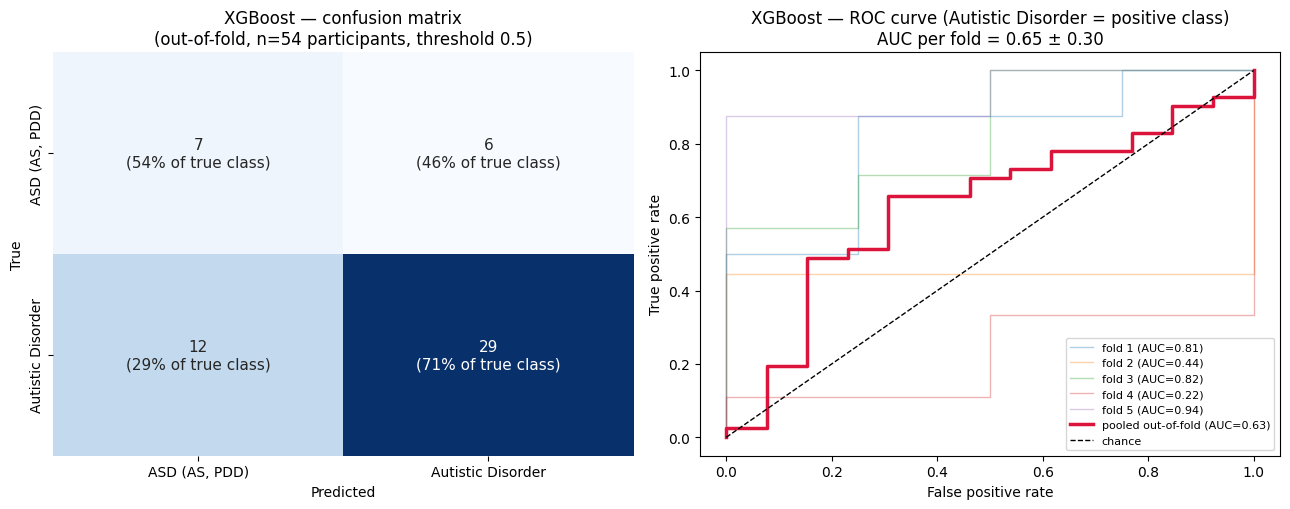

[saved] /kaggle/working/best_model_XGBoost_cm_roc.png

Sensitivity (recall Autistic Disorder) = 0.707 | Specificity (recall ASD (AS, PDD)) = 0.538
Caution: only 54 participants (13 in the minority class): one error moves a class recall by ~8 points. Compare models using the fold-to-fold std, not small gaps.


In [ ]:
_sort_cols = [SELECT_METRIC] + (['auc'] if SELECT_METRIC != 'auc' else [])
best_clf = bench_mean.sort_values(_sort_cols, ascending=False).index[0]
best_reg = bench_mean.sort_values('rmse').index[0]
print(f"Best classifier (by {SELECT_METRIC}): {best_clf}")
print(bench_mean.loc[best_clf, CLF_METRICS].round(3).to_dict())
print(f"Best ADOS regressor (by RMSE)       : {best_reg}")
print(bench_mean.loc[best_reg, REG_METRICS].round(3).to_dict())

CLASS_NAMES = list(le.classes_) if 'le' in globals() else ['ASD (AS, PDD)', 'Autistic Disorder']
folds_best = bench[best_clf]
oof = pd.concat([f['grouped'].assign(fold=f['fold']) for f in folds_best], ignore_index=True)
y_true, y_prob, y_pred = oof['y_true'].values, oof['y_prob'].values, oof['y_pred'].values

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
cm_pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100
annot = np.array([[f"{cm[i, j]}\n({cm_pct[i, j]:.0f}% of true class)" for j in range(2)] for i in range(2)])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={'fontsize': 11})
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].set_title(f"{best_clf} — confusion matrix\n(out-of-fold, n={len(oof)} participants, threshold 0.5)")

fold_aucs = []
for f in folds_best:
    g = f['grouped']
    if g['y_true'].nunique() == 2:
        fpr, tpr, _ = roc_curve(g['y_true'], g['y_prob'])
        fa = roc_auc_score(g['y_true'], g['y_prob']); fold_aucs.append(fa)
        axes[1].plot(fpr, tpr, lw=1, alpha=0.35, label=f"fold {f['fold']} (AUC={fa:.2f})")
fpr, tpr, _ = roc_curve(y_true, y_prob)
auc_pooled = roc_auc_score(y_true, y_prob)
axes[1].plot(fpr, tpr, lw=2.5, color='crimson', label=f"pooled out-of-fold (AUC={auc_pooled:.2f})")
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='chance')
axes[1].set_xlabel('False positive rate'); axes[1].set_ylabel('True positive rate')
axes[1].set_title(f"{best_clf} — ROC curve ({CLASS_NAMES[1]} = positive class)\n"
                  f"AUC per fold = {np.mean(fold_aucs):.2f} ± {np.std(fold_aucs, ddof=1):.2f}")
axes[1].legend(loc='lower right', fontsize=8)
plt.tight_layout()
out_png = os.path.join(CKPT_DIR, f"best_model_{best_clf.replace('+', '_')}_cm_roc.png")
plt.savefig(out_png, dpi=150, bbox_inches='tight'); plt.show()
print(f"[saved] {out_png}")

tn, fp, fn, tp = cm.ravel()
print(f"\nSensitivity (recall {CLASS_NAMES[1]}) = {tp / max(tp + fn, 1):.3f} | "
      f"Specificity (recall {CLASS_NAMES[0]}) = {tn / max(tn + fp, 1):.3f}")
n_min = int(min(cm.sum(axis=1)))
print(f"Caution: only {len(oof)} participants ({n_min} in the minority class): one error moves a class recall "
      f"by ~{100 / max(n_min, 1):.0f} points. Compare models using the fold-to-fold std, not small gaps.")
